In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import os
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

from peft import LoraConfig, get_peft_model

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.model.model import TransformerModel
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
MODEL_DIR = Path("/work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/")

# Load model config
with open(MODEL_DIR / "args.json", "r") as f:
    pretrain_config = json.load(f)

model_file = list(MODEL_DIR.glob("*.pt"))
assert model_file, f"No .pt files in {MODEL_DIR}"
model_file = str(model_file[0])
print(f"Model: {model_file}")

Model: /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/tiny-best_model_epoch10.pt


In [3]:
class AgeDataset(torch.utils.data.Dataset):
    """Dataset for age prediction finetuning."""
    
    def __init__(self, vocab_obj, df, scaler, mask_ratio=0.15, mask_seed=42):
        self.vocab = vocab_obj
        self.scaler = scaler
        self.mask_ratio = mask_ratio
        self.mask_seed = mask_seed
        self.gene_datas = df["data"].to_list()
        self.ages = df["age"].to_numpy()
        self.ages_norm = torch.tensor(
            scaler.transform(self.ages.reshape(-1, 1)), dtype=torch.float
        )
    
    def __getitem__(self, index):
        return self.gene_datas[index], torch.tensor(self.ages[index]).float(), self.ages_norm[index]
    
    def __len__(self):
        return len(self.ages)
    
    def collater(self, batch):
        gene_datas, ages, ages_norm = zip(*batch)
        
        # Process each sample individually with its own random mask
        all_gene_ids, all_masked, all_targets = [], [], []
        for sample in gene_datas:
            gene_ids, masked, target = self._tokenize(np.array([sample]))
            all_gene_ids.append(gene_ids)
            all_masked.append(masked)
            all_targets.append(target)
        
        return (
            torch.cat(all_gene_ids),
            torch.cat(all_masked),
            torch.cat(all_targets),
            torch.stack(ages),
            torch.stack(ages_norm)
        )

    def _tokenize(self, data):
        # Work entirely in numpy — no unnecessary tensor conversion
        if not isinstance(data, np.ndarray):
            data = np.array(data)
        data = np.nan_to_num(data, nan=-2.0)  # numpy equivalent of torch.nan_to_num
        
        tokenized = tokenize_and_pad_batch(
            data, self.vocab.CpG_ids,
            max_len=self.vocab.max_seq_len,
            vocab=self.vocab.vocab,
            pad_token="<pad>", pad_value=-2,
            append_cls=True, include_zero_gene=True,
        )
        masked = random_mask_value(
            tokenized["values"], mask_ratio=np.random.uniform(0.0, self.mask_ratio),
            mask_value=-1, pad_value=-2, mask_seed=np.random.randint(0, 1_000_000),
        )
        return tokenized["genes"], masked, tokenized["values"]



class VocabWrapper:
    """
    Builds a torchtext Vocab from a pretrained MethylGPT vocab JSON.

    The JSON maps probe IDs to their pretrained token IDs:
        {"cg00000029": 3, "ch.9.1059422R": 49158, ...}
    """

    def __init__(self, vocab_json_file, n_hvg):
        import json
        from torchtext.vocab import Vocab
        from torchtext._torchtext import Vocab as VocabPybind

        with open(vocab_json_file, "r") as f:
            probe_to_id = json.load(f)

        # Sort by token ID to reconstruct pretraining probe order
        sorted_probes = sorted(probe_to_id.items(), key=lambda x: x[1])
        self.CpG_list      = [probe for probe, _   in sorted_probes]
        token_ids     = [tid   for _,     tid in sorted_probes]

        self.CpG_ids     = np.array(token_ids, dtype=np.int64)
        self.vocab       = Vocab(VocabPybind(self.CpG_list, None))
        self.vocab.set_default_index(self.vocab["<pad>"])
        self.max_seq_len = n_hvg + 1
        self.pad_token   = "<pad>"
        self.pad_value   = -2

In [4]:
# Create vocab wrapper
vocab_wrapper = VocabWrapper(MODEL_DIR / "vocab.json", pretrain_config["n_hvg"])

# Load data splits
with open('/work/gr-fe/bryan/EpiHydra/data/02_processed/GSE40279/methylation.pkl', 'rb') as file:
    data = pickle.load(file)

meta = data["meta"].set_index("ID").copy()
cpg  = data["CpG"].copy()

valid_mask = meta["age"].notna()
n_dropped  = (~valid_mask).sum()

vocab_cpg_order = [
    vocab_wrapper.vocab.lookup_token(int(i)) for i in vocab_wrapper.CpG_ids
]

data_cpgs    = set(cpg.index)
present_cpgs = [c for c in vocab_cpg_order if c     in data_cpgs]
missing_cpgs = [c for c in vocab_cpg_order if c not in data_cpgs]


# Build (n_samples × n_vocab_cpgs) matrix — NaN for absent probes
# NaN is safe here: Age_Dataset.tokenize() calls torch.nan_to_num()
cpg_aligned = pd.DataFrame(
    np.nan,
    index=meta.index,
    columns=vocab_cpg_order,
    dtype=np.float32,
)

cpg_aligned[present_cpgs] = cpg.loc[present_cpgs].T.values

combined_df = pd.DataFrame(
    {
        "age" : meta["age"].values,
        "data": list(cpg_aligned.values),
    },
    index=meta.index,
)

train_ratio = 0.7
valid_ratio = 0.15
test_ratio = 0.15

train_df, temp_df = train_test_split(
    combined_df,
    test_size=round(1.0 - train_ratio, 10),
    random_state=42,
)
relative_valid = valid_ratio / (valid_ratio + test_ratio)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=round(1.0 - relative_valid, 10),
    random_state=42,
)

print(f"Train: {len(train_df)} samples, Valid: {len(valid_df)}, Test: {len(test_df)}")
print(f"Age range: {train_df['age'].min():.0f} - {train_df['age'].max():.0f} years")

# Fit scaler on training data
scaler = preprocessing.MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_df["age"].to_numpy().reshape(-1, 1))


# Create datasets
train_dataset = AgeDataset(vocab_wrapper, train_df, scaler, mask_ratio=0.15)
valid_dataset = AgeDataset(vocab_wrapper, valid_df, scaler, mask_ratio=0.0)
test_dataset = AgeDataset(vocab_wrapper, test_df, scaler, mask_ratio=0.0)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=16, collate_fn=train_dataset.collater, shuffle=True, drop_last=False, num_workers=0)
valid_loader = DataLoader(valid_dataset, batch_size=16, collate_fn=valid_dataset.collater, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=16, collate_fn=test_dataset.collater, num_workers=0)

print("Data loaded and ready.")

Train: 459 samples, Valid: 98, Test: 99
Age range: 21 - 101 years
Data loaded and ready.


In [ ]:
class AgePredictor(nn.Module):
    """
    Finetuned MethylGPT backbone with a trainable AttentionPoolingHead.

    Full-sequence hidden states are captured via a forward hook on
    transformer_encoder. A learned query vector then attends over all
    non-padded CpG representations to produce a scalar age prediction.

    Parameters
    ----------
    backbone  : TransformerModel — pretrained scgpt backbone
    embed_dim : int              — must match backbone layer_size
    pad_id    : int              — integer ID of <pad> token
    num_heads : int              — attention heads in pooling head
    dropout   : float
    """

    def __init__(self, backbone, embed_dim, pad_id, num_heads=4, dropout=0.1):
        super().__init__()
        self.backbone = backbone
        self.pad_id   = pad_id
        self.head     = AttentionPoolingHead(embed_dim, num_heads, dropout)


    def forward(self, gene_ids, values):
        """
        Forward pass through frozen backbone and trainable attention head.

        Hidden states from the final transformer encoder layer are captured
        via a forward hook and passed to the attention pooling head. The hook
        is stored in a local dict rather than on self to avoid shared state
        across concurrent calls.

        Parameters
        ----------
        gene_ids : (batch, seq_len) int tensor  — tokenised CpG site IDs
        values   : (batch, seq_len) float tensor — masked methylation values

        Returns
        -------
        pred : (batch,) float tensor — predicted age in [0, 1]
        """
        src_key_padding_mask = gene_ids.eq(self.pad_id)

        # Capture full sequence hidden states locally — thread safe
        captured = {}
        hook = self.backbone.transformer_encoder.register_forward_hook(
            lambda module, inp, out: captured.update({"hidden": out})
        )

        with torch.no_grad():
            _ = self.backbone(
                gene_ids, values,
                src_key_padding_mask=src_key_padding_mask,
                batch_labels=None,
            )

        hook.remove()

        sequence_hidden = captured["hidden"]
        print(
            f"sequence_hidden | "
            f"cross-sample std: {sequence_hidden.std(dim=0).mean():.6f} | "
            f"within-std: {sequence_hidden.std():.4f} | "
            f"mean: {sequence_hidden.mean():.4f} | "
            f"max: {sequence_hidden.abs().max():.4f}"
        )

        pred, _ = self.head(
            sequence_hidden,
            key_padding_mask=src_key_padding_mask,
        )
        return pred

In [5]:


# Load pretrained backbone
backbone = TransformerModel(
    len(vocab_wrapper.vocab), pretrain_config["layer_size"],
    pretrain_config["nhead"], pretrain_config["layer_size"],
    pretrain_config["nlayers"], vocab=vocab_wrapper.vocab,
    dropout=pretrain_config.get("dropout", 0.0), pad_token="<pad>",
    pad_value=-2, do_mvc=True, do_dab=False,
    use_batch_labels=False, num_batch_labels=None,
    domain_spec_batchnorm=False, n_input_bins=None,
    ecs_threshold=0.0, explicit_zero_prob=False,
    use_fast_transformer=pretrain_config.get("fast_transformer", False),
    pre_norm=pretrain_config.get("pre_norm", False),
)

# Load pretrained weights
try:
    backbone.load_state_dict(torch.load(model_file, map_location="cpu"))
    print(f"Loaded all params from {model_file}")
except RuntimeError:
    model_dict = backbone.state_dict()
    pretrained_dict = torch.load(model_file, map_location="cpu")
    compatible = {k: v for k, v in pretrained_dict.items() if k in model_dict and v.shape == model_dict[k].shape}
    model_dict.update(compatible)
    backbone.load_state_dict(model_dict)
    print(f"Loaded {len(compatible)}/{len(pretrained_dict)} compatible params")

# Simple age prediction head
class AgePredictor(nn.Module):
    def __init__(self, backbone, embed_dim):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.ReLU(),
            #nn.Dropout(0.1),
            nn.Linear(64, 1),
        )
    
    def forward(self, gene_ids, values):
        src_key_padding_mask = gene_ids.eq(vocab_wrapper.vocab["<pad>"])
        output = self.backbone(gene_ids, values, src_key_padding_mask=src_key_padding_mask, batch_labels=None)
        cell_emb = output["cell_emb"]
        print(
            f"cell_emb | "
            f"cross-sample std: {cell_emb.std(dim=0).mean():.6f} | "
            f"within-std: {cell_emb.std():.4f} | "
            f"mean: {cell_emb.mean():.4f} | "
            f"max: {cell_emb.abs().max():.4f}"
        )
        
        return self.head(cell_emb).squeeze(-1)

age_model = AgePredictor(backbone, pretrain_config["layer_size"]).to(device)
print(f"Model ready: {sum(p.numel() for p in age_model.parameters()):,} parameters")

/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer was not TransformerEncoderLayer
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/tiny-best_model_epoch10.pt
Model ready: 3,331,523 parameters


In [19]:
config = LoraConfig(
    r=8,                              # Lowered — see note below
    lora_alpha=4,
    target_modules=["Wqkv", "out_proj","linear1" , "linear2"],  # Correct names for this architecture
    lora_dropout=0.1,
)

age_model.backbone = get_peft_model(age_model.backbone, config)
age_model.backbone.print_trainable_parameters()

trainable params: 32,264 || all params: 3,359,562 || trainable%: 0.9604


In [7]:
#for name, param in age_model.backbone.named_parameters():
#    if "value_encoder" in name:
#        param.requires_grad = True
#        print(f"Unfrozen: {name}")

#age_model.backbone.print_trainable_parameters()

Unfrozen: base_model.model.value_encoder.linear1.base_layer.weight
Unfrozen: base_model.model.value_encoder.linear1.base_layer.bias
Unfrozen: base_model.model.value_encoder.linear1.lora_A.default.weight
Unfrozen: base_model.model.value_encoder.linear1.lora_B.default.weight
Unfrozen: base_model.model.value_encoder.linear2.base_layer.weight
Unfrozen: base_model.model.value_encoder.linear2.base_layer.bias
Unfrozen: base_model.model.value_encoder.linear2.lora_A.default.weight
Unfrozen: base_model.model.value_encoder.linear2.lora_B.default.weight
Unfrozen: base_model.model.value_encoder.norm.weight
Unfrozen: base_model.model.value_encoder.norm.bias
trainable params: 133,472 || all params: 3,456,354 || trainable%: 3.8616


In [ ]:
# ✅ CHANGE 1: Filter to only trainable (LoRA) params from backbone
optimizer = torch.optim.Adam([
    {"params": [p for p in age_model.backbone.parameters() if p.requires_grad], "lr": 1e-4},
    {"params": age_model.head.parameters(), "lr": 1e-4},
], weight_decay=0.00)

criterion = nn.MSELoss()
NUM_EPOCHS = 3  # Demo: use 50+ for real training

scaler_amp = torch.cuda.amp.GradScaler()

for epoch in range(NUM_EPOCHS):
    age_model.train()
    train_losses = []
    for batch_idx, (gene_ids, masked_vals, target_vals, ages, ages_norm) in enumerate(train_loader):
        gene_ids = gene_ids.to(device)
        masked_vals = masked_vals.to(device)
        ages_norm = ages_norm.to(device).squeeze()
        
        with torch.cuda.amp.autocast():
            pred = age_model(gene_ids, masked_vals).squeeze()  # ✅ CHANGE 2: squeeze pred to match ages_norm shape
            loss = criterion(pred, ages_norm)
        
        optimizer.zero_grad()
        scaler_amp.scale(loss).backward()
        #for name, param in age_model.named_parameters():
        #    if param.requires_grad and param.grad is not None:
        #        print(f"{name}: grad_norm={param.grad.norm().item():.6f}")
        #    elif param.requires_grad and param.grad is None:
        #        print(f"{name}: NO GRADIENT ⚠️")
        scaler_amp.unscale_(optimizer)
        # ✅ CHANGE 3: Only clip gradients of trainable params — frozen weights have no grad
        #torch.nn.utils.clip_grad_norm_(
        #    [p for p in age_model.parameters() if p.requires_grad], 1.0
        #)
        scaler_amp.step(optimizer)
        scaler_amp.update()
        
        train_losses.append(loss.item())
        if (batch_idx + 1) % 10 == 0:
            print(f"  Epoch {epoch+1}, Batch {batch_idx+1}, Loss: {np.mean(train_losses[-10:]):.4f}")
    
    # Validate
    age_model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for gene_ids, masked_vals, target_vals, ages, ages_norm in valid_loader:
            gene_ids = gene_ids.to(device)
            target_vals = target_vals.to(device)
            with torch.cuda.amp.autocast():
                pred = age_model(gene_ids, target_vals)
            pred_age = scaler.inverse_transform(pred.float().cpu().numpy().reshape(-1, 1)).flatten()
            all_preds.extend(pred_age)
            all_labels.extend(ages.numpy())
    
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    mae = np.mean(np.abs(all_preds - all_labels))
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Train loss: {np.mean(train_losses):.4f}, Valid MAE: {mae:.2f} years")


cell_emb | cross-sample std: 0.014363 | within-std: 0.1383 | mean: 0.0141 | max: 1.0866
cell_emb | cross-sample std: 0.013116 | within-std: 0.1382 | mean: 0.0139 | max: 1.0870
cell_emb | cross-sample std: 0.012615 | within-std: 0.1381 | mean: 0.0140 | max: 1.0887
cell_emb | cross-sample std: 0.013768 | within-std: 0.1382 | mean: 0.0140 | max: 1.0869
cell_emb | cross-sample std: 0.012037 | within-std: 0.1381 | mean: 0.0141 | max: 1.0865
cell_emb | cross-sample std: 0.014208 | within-std: 0.1381 | mean: 0.0141 | max: 1.0880
cell_emb | cross-sample std: 0.013977 | within-std: 0.1382 | mean: 0.0140 | max: 1.0880
cell_emb | cross-sample std: 0.015475 | within-std: 0.1385 | mean: 0.0140 | max: 1.0866
cell_emb | cross-sample std: 0.013959 | within-std: 0.1383 | mean: 0.0140 | max: 1.0870
cell_emb | cross-sample std: 0.017657 | within-std: 0.1389 | mean: 0.0142 | max: 1.0900
  Epoch 1, Batch 10, Loss: 0.2947
cell_emb | cross-sample std: 0.014831 | within-std: 0.1383 | mean: 0.0141 | max: 1.086

cell_emb | cross-sample std: 0.011474 | within-std: 0.2581 | mean: 0.0145 | max: 1.0040
cell_emb | cross-sample std: 0.008966 | within-std: 0.2615 | mean: 0.0146 | max: 0.9902
cell_emb | cross-sample std: 0.009366 | within-std: 0.2569 | mean: 0.0144 | max: 0.9971
cell_emb | cross-sample std: 0.007514 | within-std: 0.2598 | mean: 0.0145 | max: 0.9925
cell_emb | cross-sample std: 0.007320 | within-std: 0.2608 | mean: 0.0146 | max: 0.9911
cell_emb | cross-sample std: 0.009103 | within-std: 0.2581 | mean: 0.0145 | max: 0.9970
cell_emb | cross-sample std: 0.009390 | within-std: 0.2587 | mean: 0.0145 | max: 0.9965
cell_emb | cross-sample std: 0.011043 | within-std: 0.2580 | mean: 0.0145 | max: 1.0008
cell_emb | cross-sample std: 0.011727 | within-std: 0.2581 | mean: 0.0145 | max: 0.9994
cell_emb | cross-sample std: 0.010679 | within-std: 0.2582 | mean: 0.0145 | max: 0.9994
cell_emb | cross-sample std: 0.009030 | within-std: 0.2582 | mean: 0.0145 | max: 0.9944
cell_emb | cross-sample std: 0.0

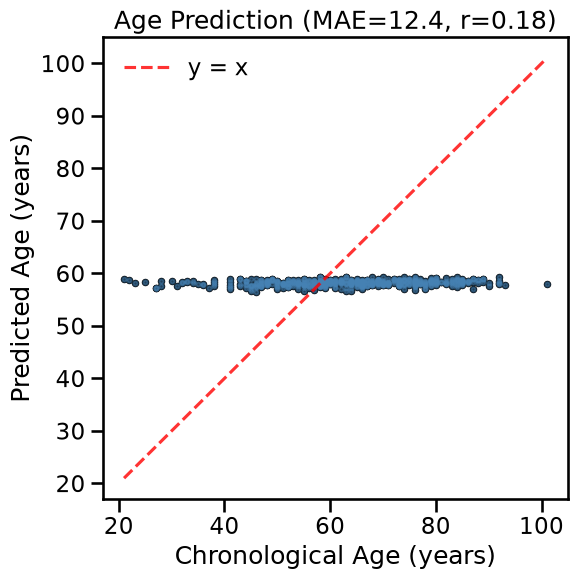

In [12]:
# Evaluate on test set
age_model.eval()
test_preds, test_labels = [], []
with torch.no_grad():
    for gene_ids, masked_vals, target_vals, ages, ages_norm in train_loader:
        gene_ids = gene_ids.to(device)
        target_vals = target_vals.to(device)
        with torch.cuda.amp.autocast():
            pred = age_model(gene_ids, target_vals)
        pred_age = scaler.inverse_transform(pred.float().cpu().numpy().reshape(-1, 1)).flatten()
        test_preds.extend(pred_age)
        test_labels.extend(ages.numpy())

test_preds = np.array(test_preds)
test_labels = np.array(test_labels)

# Metrics
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import pearsonr

mae = mean_absolute_error(test_labels, test_preds)
r2 = r2_score(test_labels, test_preds)
r, _ = pearsonr(test_labels, test_preds)

print(f"Test MAE: {mae:.2f} years")
print(f"Test R²: {r2:.3f}")
print(f"Test Pearson r: {r:.3f}")

# Scatter plot with aquarel theme
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
# Outline layer
ax.scatter(test_labels, test_preds, s=15, c="black", alpha=1, zorder=1)
# Data layer
ax.scatter(test_labels, test_preds, s=10, alpha=0.5, c="steelblue", zorder=2)
lims = [min(test_labels.min(), test_preds.min()), max(test_labels.max(), test_preds.max())]
ax.plot(lims, lims, "r--", alpha=0.8, label="y = x")
ax.set_xlabel("Chronological Age (years)")
ax.set_ylabel("Predicted Age (years)")
ax.set_title(f"Age Prediction (MAE={mae:.1f}, r={r:.2f})")
ax.legend(frameon=False)

plt.show()

In [9]:
age_model.train()
with torch.no_grad():
    gene_ids, masked_vals, target_vals, ages, ages_norm = next(iter(test_loader))
    gene_ids = gene_ids.to(device)
    masked_vals = masked_vals.to(device)
    
    src_key_padding_mask = gene_ids.eq(vocab_wrapper.vocab["<pad>"])
    
    with torch.cuda.amp.autocast():
        output = age_model.backbone(gene_ids, masked_vals,
                                    src_key_padding_mask=src_key_padding_mask,
                                    batch_labels=None)
        emb = output["cell_emb"]
    
    print(f"cell_emb shape:            {emb.shape}")
    print(f"cell_emb within-std:       {emb.std():.6f}")
    print(f"cell_emb cross-sample std: {emb.std(dim=0).mean():.6f}")
    
    # Also check predictions
    with torch.cuda.amp.autocast():
        pred = age_model.head(emb).squeeze()
    
    print(f"\npred std:  {pred.std():.6f}")
    print(f"pred mean: {pred.mean():.6f}")
    print(f"pred:      {pred[:8]}")
    print(f"target:    {ages_norm.squeeze()[:8]}")


cell_emb shape:            torch.Size([16, 64])
cell_emb within-std:       0.270613
cell_emb cross-sample std: 0.058609

pred std:  0.052032
pred mean: 0.470215
pred:      tensor([0.4126, 0.5073, 0.4512, 0.4048, 0.5161, 0.5293, 0.3911, 0.4729],
       device='cuda:0', dtype=torch.float16)
target:    tensor([0.7500, 0.4000, 0.4250, 0.5125, 0.5875, 0.2375, 0.8125, 0.8500])


In [11]:
print(f"masked_vals cross-sample std: {masked_vals.float().std(dim=0).mean():.6f}")
print(f"masked_vals unique values: {masked_vals.unique()}")
print(f"masked_vals sample 0 == sample 1: {(masked_vals[0] == masked_vals[1]).all()}")


masked_vals cross-sample std: 0.775215
masked_vals unique values: tensor([-2.0000, -1.0000,  0.0000,  ...,  0.9974,  0.9974,  0.9975],
       device='cuda:0')
masked_vals sample 0 == sample 1: False


In [ ]:
age_model.eval()

with torch.no_grad():
    # Grab one batch
    gene_ids, masked_vals, target_vals, ages, ages_norm = next(iter(train_loader))
    gene_ids = gene_ids.to(device)
    masked_vals = masked_vals.to(device)

    # Access the underlying model through PEFT wrappers
    backbone = age_model.backbone.base_model.model

    # Step 1 — GeneEncoder output
    gene_emb = backbone.encoder(gene_ids)
    print(f"GeneEncoder:")
    print(f"  shape:             {gene_emb.shape}")
    print(f"  within-tensor std: {gene_emb.std():.6f}")
    print(f"  cross-sample std:  {gene_emb.std(dim=0).mean():.6f}")

    # Step 2 — ContinuousValueEncoder output
    val_emb = backbone.value_encoder(masked_vals.unsqueeze(-1))
    print(f"\nValueEncoder:")
    print(f"  shape:             {val_emb.shape}")
    print(f"  within-tensor std: {val_emb.std():.6f}")
    print(f"  cross-sample std:  {val_emb.std(dim=0).mean():.6f}")

    # Step 3 — Combined (what the transformer actually sees)
    combined = gene_emb + val_emb
    print(f"\nCombined (gene + value):")
    print(f"  within-tensor std: {combined.std():.6f}")
    print(f"  cross-sample std:  {combined.std(dim=0).mean():.6f}")


In [17]:
# Collect embeddings for a batch
age_model.eval()
age_model.backbone.eval()

embeddings = []
true_ages_list = []

with torch.no_grad():
    for i, (gene_ids, masked_vals, target_vals, ages, ages_norm) in enumerate(test_loader):
        if i >= 10:  # just 5 batches
            break
        gene_ids    = gene_ids.to(device)
        masked_vals = masked_vals.to(device)

        with torch.cuda.amp.autocast():
            # Get raw backbone embeddings before head
            src_key_padding_mask = gene_ids.eq(vocab_wrapper.vocab["<pad>"])
            hidden = age_model.backbone(gene_ids, masked_vals, src_key_padding_mask)  # adjust to your method name
        
        embeddings.append(hidden['cell_emb'].float().cpu())
        true_ages_list.extend(ages.numpy())

embeddings = torch.cat(embeddings, dim=0)
print(f"Embedding shape: {embeddings.shape}")
print(f"Embedding mean std across samples: {embeddings.std(dim=0).mean():.6f}")
print(f"Embedding mean: {embeddings.mean():.6f}")
# If std is near 0, backbone is outputting near-constant embeddings


Embedding shape: torch.Size([99, 64])
Embedding mean std across samples: 0.012627
Embedding mean: 0.014459


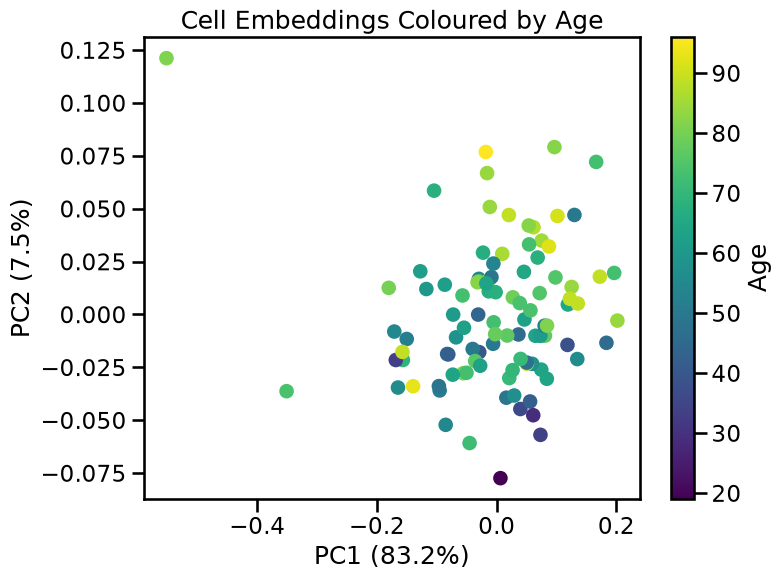

Variance explained by PC1+PC2: 90.8%


In [18]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA on embeddings
pca = PCA(n_components=2)
emb_2d = pca.fit_transform(embeddings)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(emb_2d[:, 0], emb_2d[:, 1], 
                      c=true_ages_list, cmap='viridis')
plt.colorbar(scatter, label='Age')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Cell Embeddings Coloured by Age")
plt.show()

print(f"Variance explained by PC1+PC2: {pca.explained_variance_ratio_[:2].sum():.1%}")
